In [3]:
import torch

BATCH_SIZE = 2
NUM_HEADS = 8
SEQ_LEN = 12
HEAD_DIM = 16
dtype = torch.float16

Q = (
        torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="mps"
        )
        .normal_(mean=0.0, std=0.5)
        .requires_grad_()
    )
K = (
    torch.empty(
        (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="mps"
    )
    .normal_(mean=0.0, std=0.5)
    .requires_grad_()
)
V = (
    torch.empty(
        (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="mps"
    )
    .normal_(mean=0.0, std=0.5)
    .requires_grad_()
)

P = torch.matmul(Q, K.transpose(-2, -1)) 
P.shape

# Batch Size = 2
# Num Heads = 4
S = torch.randint(0, 10, (2,4))
S

tensor([[7, 6, 1, 9],
        [0, 2, 4, 9]])

In [ ]:
import torch
import triton 
import triton.language as tl 

@triton.jit
def _attn_fwd_inner(
    O_block,
    l_i,
    m_i,
    Q_block,
    K_block_ptr,
    V_block_ptr,
    block_index_q,
    softmax_scale,
    BLOCK_SIZE_Q: tl.constexpr,
    BLOCK_SIZE_KV: tl.constexpr,
    STAGE: tl.constexpr,
    offs_q: tl.constexpr,
    offs_kv: tl.constexpr,
    SEQ_LEN: tl.constexpr,
):  
    # range of values handled by this program
    if STAGE == 1:
        # From 0 to the left of the diagonal in the causal case
        lo, hi = 0, BLOCK_SIZE_Q
    elif STAGE == 2:
        # Used only for the blocks in which there is transition from non-causal to causal
        lo, hi = block_index_q * BLOCK_SIZE_Q, (block_index_q + 1) * BLOCK_SIZE_Q
        lo = tl.multiple_of(lo, BLOCK_SIZE_Q)
    else:
        # Only used for non-causal attention
        lo, hi = 0, SEQ_LEN
    
    K_block_ptr = tl.advance(K_block_ptr, (0, lo))
    V_block_ptr = tl.advance(V_block_ptr, (lo, 0))

    # loop over k, v and update accumulator
    for start_kv in range(lo, hi, BLOCK_SIZE_KV):
        # Just let the compiler know that start_n in an multiple of BLOCK_N, so the compiler can do optimizations
        start_kv = tl.multiple_of(start_kv, BLOCK_SIZE_KV)

        # --- compute qk ----
        K_block = tl.load(K_block_ptr)
        QK_block = tl.dot(Q_block, K_block)

        if STAGE == 2:
            mask = offs_q[:, None] >= (start_kv + offs_kv[None, :])
            QK_block = QK_block * softmax_scale + tl.where(mask, 0, -1.0e6)
            mij = tl.maximum(m_i, tl.max(QK_block, 1) * softmax_scale)
            QK_block -= mij[:, None]
        else:
            # Compute the maximum value of qk or keep the old max value
            m_ij = tl.maximum(m_i, tl.max(QK_block, 1) * softmax_scale)
            QK_block = QK_block * softmax_scale - m_ij[:, None]

        # Compute the exponential of each dot product, so now we are computing exp(qk_ij - m_ij)
        P_block = tl.math.exp(QK_block)
        # Compute the sum by rows of the attention scores
        l_ij = tl.sum(P_block, 1)

        # This is the exponential of each dot product, so new we are computing 
        alpha = tl.math.exp(m_i - m_ij)
        # Apply the correction factor to the previous l_i and add the new l_ij
        l_i = l_i * alpha + l_ij

        V_block = tl.load(V_block_ptr)
        P_block = P_block.to(tl.float16)
        # This computes the following: O_new = P x V + O_old * alpha
        O_block = O_block * alpha[:, None]
        O_block = tl.dot(P_block, V_block, O_block)

        m_i = m_ij

        # Move to the next block of K and V
        V_block_ptr = tl.advance(V_block_ptr, (BLOCK_SIZE_KV, 0))
        K_block_ptr = tl.advance(K_block_ptr, (0, BLOCK_SIZE_KV))
    return O_block, l_i, m_i

@triton.jit
def _attn_fwd(
    Q, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM Q[index_batch, index_head, :, :]
    K, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM 
    V, # BATHC_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
    softmax_scale,
    M, # BATCH_SIZE, NUM_HEADS, SEQ_LEN
    O, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
    stride_Q_batch,
    stride_Q_head,
    stride_Q_seq,
    stride_Q_dim,
    stride_K_batch,
    stride_K_head,
    stride_K_seq,
    stride_K_dim,
    stride_V_batch,
    stride_V_head,
    stride_V_seq,
    stride_V_dim,
    stride_O_batch,
    stride_O_head,
    stride_O_seq,
    stride_O_dim,
    BATCH_SIZE,
    NUM_HEADS: tl.constexpr,
    SEQ_LEN: tl.constexpr,
    HEAD_DIM: tl.constexpr,
    BLOCK_SIZE_Q: tl.constexpr,
    BLOCK_SIZE_KV: tl.constexpr,
    STAGE: tl.constexpr,
):  
    tl.static_assert(BLOCK_SIZE_KV <= HEAD_DIM, "BLOCK_SIZE_KV must be less than or equal to HEAD_DIM")

    # This indicates whcih block in the sequence length to process
    block_index_q = tl.program_id(0)

    # This indicates which batch and head to process
    index_batch_head = tl.program_id(1)
    # This indicates which batch this program is associated with (each batch has NUM_HEADS heads)
    index_batch = index_batch_head // NUM_HEADS
    # This indicates the position of the head in the batch
    index_head = index_batch_head % NUM_HEADS

    # This allows to get the (SEQ_LEN, HEAD_DIM) block in the Q, K, V by selectign indexing it by batch and head
    qkv_offset = (
        index_batch.to(tl.int64) * stride_Q_batch + 
        index_head.to(tl.int64) * stride_Q_head
    )

    Q_block_ptr = tl.make_block_ptr(
        base = Q + qkv_offset, # Q[index_batch, index_head, :, :]
        shape = (SEQ_LEN, HEAD_DIM), # (SEQ_LEN, HEAD_DIM) block in the Q, K, V
        strides = (stride_Q_seq, stride_Q_dim),
        offsets = (block_index_q * BLOCK_SIZE_Q, 0), # Q[index_batch, index_head, block_index_q * BLOCK_SIZE_Q : block_index_q * BLOCK_SIZE_Q + BLOCK_SIZE_Q]
        block_shape = (BLOCK_SIZE_Q, HEAD_DIM),
        order = (1, 0), # (SEQ_LEN, HEAD_DIM)
    )

    V_block_ptr = tl.make_block_ptr(
        base = V + qkv_offset, # V[index_batch, index_head, : , :]
        shape = (SEQ_LEN, HEAD_DIM),
        strides = (stride_V_seq, stride_V_dim),
        offsets = (0, 0),
        block_shape = (BLOCK_SIZE_KV, HEAD_DIM),
        order = (1, 0),
    )

    K_block_ptr = tl.make_block_ptr(
        base = K + qkv_offset, # K[index_batch, index_head, :, :]
        shape = (SEQ_LEN, HEAD_DIM),
        strides = (
            stride_K_dim,
            stride_K_seq,
        ), # We invert the strides w.r.t Q, so we transpose the matrix 
        offsets = (0, 0),
        block_shape = (HEAD_DIM, BLOCK_SIZE_KV),
        order = (0, 1),
    )

    O_block_ptr = tl.make_block_ptr( # O[index_batch, index_head, block_index_q * BLOCK_SIZE_Q : block_index]
        base = O + qkv_offset, # O[index_batch, index_head, :, :]
        shape = (SEQ_LEN, HEAD_DIM),
        strides = (stride_O_dim, stride_O_seq),
        offsets = (block_index_q * BLOCK_SIZE_Q, 0), # O[index_batch, index_head, block_index_q * BLOCK_SIZE_Q : block_index_q * BLOCK_SIZE_Q + BLOCK_SIZE_Q, :]
        block_shape = (BLOCK_SIZE_Q, HEAD_DIM),
        order = (1, 0),
    )
    
    # offs_q: the offsets for the tokens in the Q block
    offs_q = block_index_q * BLOCK_SIZE_Q + tl.arange(0, BLOCK_SIZE_Q)
    # if pid = 3, then offs_q = 3*4 = 12 + (0, 1, 2, 3) = 12, 13, 14, 15

    # offs_k: the offsets for the tokens in the K block
    offs_k = tl.arange(0, BLOCK_SIZE_KV)

    # offs_v: the offsets for the tokens in the V block
    offs_v = tl.arange(0, BLOCK_SIZE_KV)
    
    # m_i: the running maximum. We have one for each query in the Q block
    m_i = tl.zeros([BLOCK_SIZE_Q], dtype=tl.float32) - float("inf")

    # l_i: the running logsumexp for each query (as we sum the attention scores by rows)
    l_i = tl.zeros([BLOCK_SIZE_Q], dtype=tl.float32) + 1.0 # the +1.0 if for numerical stability

    # acc: the accumulator for the output, which is a group of rows of the O matrix
    O_block = tl.zeros([BLOCK_SIZE_Q, BLOCK_SIZE_KV], dtype=tl.float32)

    # load the Q block: it will stay in SRAM throughout the loop
    Q_block = tl.load(Q_block_ptr)

    # Stage : 3 if causal else 1
    if STAGE == 1 or STAGE == 3:
        # This step runs for non-causal attention or for the block to the left of the diagonal in the causal case
        O_block, l_i, m_i = _attn_fwd_inner(
            O_block,
            l_i,
            m_i,
            Q_block,
            K_block_ptr,
            V_block_ptr,
            block_index_q,
            softmax_scale,
            BLOCK_SIZE_Q,
            BLOCK_SIZE_KV,
            4 - STAGE,
            offs_q,
            offs_k,
            SEQ_LEN,
        )
    
    if STAGE == 3:
        # This step runs for the blocks to the right of the diagonal in the causal case
        O_block, l_i, m_i = _attn_fwd_inner(
            O_block,
            l_i,
            m_i,
            Q_block,
            K_block_ptr,
            V_block_ptr,
            block_index_q,
            softmax_scale,
            BLOCK_SIZE_Q,
            BLOCK_SIZE_KV,
            2,
            offs_q,
            offs_k,
            SEQ_LEN,
        )
    

class TritonAttention(torch.autograd.Function):
    @staticmethod
    def forward(ctx, Q, K, V, causal, softmax_scale):
        HEAD_DIM_Q, HEAD_DIM_K = Q.shape[-1], K.shape[-1]
        HEAD_DIM_V = V.shape[-1]

        BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM = Q.shape

        assert HEAD_DIM_Q == HEAD_DIM_K and HEAD_DIM_K == HEAD_DIM_V
        
        O = torch.empty_like(Q)
        stage = 3 if causal else 1

        grid = lambda args: (
            # celing(SEQ_LEN / BLOCK_SIZE_Q) = How many blocks of Q we have. 
            triton.cdiv(SEQ_LEN, args["BLOCK_SIZE_Q"]), # Which group of queries are we going to work with ?
            BATCH_SIZE * NUM_HEADS, # Group of thereds : Which head of which batch are we going to work with 
            1, # Z dim in CUDA launch grid
        )

        # Number of parallel programs: (BATCH_SIZE * NUM_HEADS * NUM_BLOCKS_Q)

        # M is logsum
        M = torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN), device=Q.device, dtype=torch.float32
        )

        _attn_fwd[grid](
            Q=Q, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            K=K, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            V=V, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            softmax_scale=softmax_scale,
            M=M, # BATCH_SIZE, NUM_HEADS, SEQ_LEN
            O=O, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            stride_Q_batch=Q.stride(0),
            stride_Q_head=Q.stride(1),
            stride_Q_seq=Q.stride(2),
            stride_Q_dim=Q.stride(3),
            stride_K_batch=K.stride(0),
            stride_K_head=K.stride(1),
            stride_K_seq=K.stride(2),
            stride_K_dim=K.stride(3),
            stride_V_batch=V.stride(0),
            stride_V_head=V.stride(1),
            stride_V_seq=V.stride(2),
            stride_V_dim=V.stride(3),
            stride_O_batch=O.stride(0),
            stride_O_head=O.stride(1),
            stride_O_seq=O.stride(2),
            stride_O_dim=O.stride(3),
            BATCH_SIZE=Q.shape[0],
            NUM_HEADS=Q.shape[1],
            SEQ_LEN=Q.shape[2],
            HEAD_DIM=Q.shape[3],
            STAGE=stage,
        )
        
        ctx.save_for_backward(Q, K, V, O, M)
        ctx.grid = grid
        ctx.softmax_scale = softmax_scale
        ctx.HEAD_DIM = HEAD_DIM_K
        ctx.causal = causal
        return 0


def test_op(BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM, causal, dtype=torch.float16):
    Q = (
        torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="cuda"
        )
        .normal_(mean=0.0, std=0.5)
        .requires_grad()
    )

    K = (
        torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="cuda"
        )
        .normal_(mean=0.0, std=0.5)
        .requires_grad_()
    )

    V = (
        torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="cuda"
        )
        .normal_(mean=0.0, dtd=0.5)
        .requires_grad()
    )

    softmax_scale = 1 / (HEAD_DIM**0.5)
    dO = torch.rand_like(Q) # Needed for the backward pass

    # reference implementation
    MASK = torch.tril(torch.ones((SEQ_LEN, SEQ_LEN), device="cuda"))
    P = torch.matmul(Q, K.transpose(2,3)) * softmax_scale
    if causal:
        P[:, :, MASK == 0] = float("-inf")
    P = torch.softmax(P.float(), dim=-1).half()
    ref_O = torch.matmul(P, V)
    ref_O.backward(dO)
    ref_dV, V.grad = V.grad.clone(), None
    ref_dK, K.grad = K.grad.clone(), None
    ref_dQ, Q.grad = Q.grad.clone(), None

    # titon implementation
    tri_out = TritonAttention.apply(Q, K, V, causal, softmax_scale).half()
    tri_out.backward(dO)
    tri_dV, V.grad = V.grad.clone(), None
    tri_dK, K.grad = K.grad.clone(), None
    tri_dQ, Q.grad = Q.grad.clone(), None

    # Compare
    rtol = 0.0
    atol = 1e-2
    assert torch.allclose(ref_O, tri_out, atol=atol, rtol=rtol)
    assert torch.allclose(ref_dK, tri_dK, atol=atol, rtol=rtol)
    assert torch.allclose(ref_dQ, tri_dQ, atol=atol, rtol=rtol)
    assert torch.allclose(ref_dV, tri_dK, atol=atol, rtol=rtol)

In [ ]:
import torch
import triton 
import triton.language as tl 

@triton.jit
def _attn_fwd_inner(
    O_block,
    l_i,
    m_i,
    Q_block,
    K_block_ptr,
    V_block_ptr,
    block_index_q,
    softmax_scale,
    BLOCK_SIZE_Q: tl.constexpr,
    BLOCK_SIZE_KV: tl.constexpr,
    STAGE: tl.constexpr,
    offs_q: tl.constexpr,
    offs_kv: tl.constexpr,
    SEQ_LEN: tl.constexpr,
):  
    # range of values handled by this program
    if STAGE == 1:
        # From 0 to the left of the diagonal in the causal case
        lo, hi = 0, BLOCK_SIZE_Q
    elif STAGE == 2:
        # Used only for the blocks in which there is transition from non-causal to causal
        lo, hi = block_index_q * BLOCK_SIZE_Q, (block_index_q + 1) * BLOCK_SIZE_Q
        lo = tl.multiple_of(lo, BLOCK_SIZE_Q)
    else:
        # Only used for non-causal attention
        lo, hi = 0, SEQ_LEN
    
    K_block_ptr = tl.advance(K_block_ptr, (0, lo))
    V_block_ptr = tl.advance(V_block_ptr, (lo, 0))

    # loop over k, v and update accumulator
    for start_kv in range(lo, hi, BLOCK_SIZE_KV):
        # Just let the compiler know that start_n in an multiple of BLOCK_N, so the compiler can do optimizations
        start_kv = tl.multiple_of(start_kv, BLOCK_SIZE_KV)

        # --- compute qk ----
        K_block = tl.load(K_block_ptr)
        QK_block = tl.dot(Q_block, K_block)

        if STAGE == 2:
            mask = offs_q[:, None] >= (start_kv + offs_kv[None, :])
            QK_block = QK_block * softmax_scale + tl.where(mask, 0, -1.0e6)
            mij = tl.maximum(m_i, tl.max(QK_block, 1) * softmax_scale)
            QK_block -= mij[:, None]
        else:
            # Compute the maximum value of qk or keep the old max value
            m_ij = tl.maximum(m_i, tl.max(QK_block, 1) * softmax_scale)
            QK_block = QK_block * softmax_scale - m_ij[:, None]

        # Compute the exponential of each dot product, so now we are computing exp(qk_ij - m_ij)
        P_block = tl.math.exp(QK_block)
        # Compute the sum by rows of the attention scores
        l_ij = tl.sum(P_block, 1)

        # This is the exponential of each dot product, so new we are computing 
        alpha = tl.math.exp(m_i - m_ij)
        # Apply the correction factor to the previous l_i and add the new l_ij
        l_i = l_i * alpha + l_ij

        V_block = tl.load(V_block_ptr)
        P_block = P_block.to(tl.float16)
        # This computes the following: O_new = P x V + O_old * alpha
        O_block = O_block * alpha[:, None]
        O_block = tl.dot(P_block, V_block, O_block)

        m_i = m_ij

        # Move to the next block of K and V
        V_block_ptr = tl.advance(V_block_ptr, (BLOCK_SIZE_KV, 0))
        K_block_ptr = tl.advance(K_block_ptr, (0, BLOCK_SIZE_KV))
    return O_block, l_i, m_i

@triton.jit
def _attn_fwd(
    Q, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM Q[index_batch, index_head, :, :]
    K, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM 
    V, # BATHC_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
    softmax_scale,
    M, # BATCH_SIZE, NUM_HEADS, SEQ_LEN
    O, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
    stride_Q_batch,
    stride_Q_head,
    stride_Q_seq,
    stride_Q_dim,
    stride_K_batch,
    stride_K_head,
    stride_K_seq,
    stride_K_dim,
    stride_V_batch,
    stride_V_head,
    stride_V_seq,
    stride_V_dim,
    stride_O_batch,
    stride_O_head,
    stride_O_seq,
    stride_O_dim,
    BATCH_SIZE,
    NUM_HEADS: tl.constexpr,
    SEQ_LEN: tl.constexpr,
    HEAD_DIM: tl.constexpr,
    BLOCK_SIZE_Q: tl.constexpr,
    BLOCK_SIZE_KV: tl.constexpr,
    STAGE: tl.constexpr,
):  
    tl.static_assert(BLOCK_SIZE_KV <= HEAD_DIM, "BLOCK_SIZE_KV must be less than or equal to HEAD_DIM")

    # This indicates whcih block in the sequence length to process
    block_index_q = tl.program_id(0)

    # This indicates which batch and head to process
    index_batch_head = tl.program_id(1)
    # This indicates which batch this program is associated with (each batch has NUM_HEADS heads)
    index_batch = index_batch_head // NUM_HEADS
    # This indicates the position of the head in the batch
    index_head = index_batch_head % NUM_HEADS

    # This allows to get the (SEQ_LEN, HEAD_DIM) block in the Q, K, V by selectign indexing it by batch and head
    qkv_offset = (
        index_batch.to(tl.int64) * stride_Q_batch + 
        index_head.to(tl.int64) * stride_Q_head
    )

    Q_block_ptr = tl.make_block_ptr(
        base = Q + qkv_offset, # Q[index_batch, index_head, :, :]
        shape = (SEQ_LEN, HEAD_DIM), # (SEQ_LEN, HEAD_DIM) block in the Q, K, V
        strides = (stride_Q_seq, stride_Q_dim),
        offsets = (block_index_q * BLOCK_SIZE_Q, 0), # Q[index_batch, index_head, block_index_q * BLOCK_SIZE_Q : block_index_q * BLOCK_SIZE_Q + BLOCK_SIZE_Q]
        block_shape = (BLOCK_SIZE_Q, HEAD_DIM),
        order = (1, 0), # (SEQ_LEN, HEAD_DIM)
    )

    V_block_ptr = tl.make_block_ptr(
        base = V + qkv_offset, # V[index_batch, index_head, : , :]
        shape = (SEQ_LEN, HEAD_DIM),
        strides = (stride_V_seq, stride_V_dim),
        offsets = (0, 0),
        block_shape = (BLOCK_SIZE_KV, HEAD_DIM),
        order = (1, 0),
    )

    K_block_ptr = tl.make_block_ptr(
        base = K + qkv_offset, # K[index_batch, index_head, :, :]
        shape = (SEQ_LEN, HEAD_DIM),
        strides = (
            stride_K_dim,
            stride_K_seq,
        ), # We invert the strides w.r.t Q, so we transpose the matrix 
        offsets = (0, 0),
        block_shape = (HEAD_DIM, BLOCK_SIZE_KV),
        order = (0, 1),
    )

    O_block_ptr = tl.make_block_ptr( # O[index_batch, index_head, block_index_q * BLOCK_SIZE_Q : block_index]
        base = O + qkv_offset, # O[index_batch, index_head, :, :]
        shape = (SEQ_LEN, HEAD_DIM),
        strides = (stride_O_dim, stride_O_seq),
        offsets = (block_index_q * BLOCK_SIZE_Q, 0), # O[index_batch, index_head, block_index_q * BLOCK_SIZE_Q : block_index_q * BLOCK_SIZE_Q + BLOCK_SIZE_Q, :]
        block_shape = (BLOCK_SIZE_Q, HEAD_DIM),
        order = (1, 0),
    )
    
    # offs_q: the offsets for the tokens in the Q block
    offs_q = block_index_q * BLOCK_SIZE_Q + tl.arange(0, BLOCK_SIZE_Q)
    # if pid = 3, then offs_q = 3*4 = 12 + (0, 1, 2, 3) = 12, 13, 14, 15

    # offs_k: the offsets for the tokens in the K block
    offs_k = tl.arange(0, BLOCK_SIZE_KV)

    # offs_v: the offsets for the tokens in the V block
    offs_v = tl.arange(0, BLOCK_SIZE_KV)
    
    # m_i: the running maximum. We have one for each query in the Q block
    m_i = tl.zeros([BLOCK_SIZE_Q], dtype=tl.float32) - float("inf")

    # l_i: the running logsumexp for each query (as we sum the attention scores by rows)
    l_i = tl.zeros([BLOCK_SIZE_Q], dtype=tl.float32) + 1.0 # the +1.0 if for numerical stability

    # acc: the accumulator for the output, which is a group of rows of the O matrix
    O_block = tl.zeros([BLOCK_SIZE_Q, BLOCK_SIZE_KV], dtype=tl.float32)

    # load the Q block: it will stay in SRAM throughout the loop
    Q_block = tl.load(Q_block_ptr)

    # Stage : 3 if causal else 1
    if STAGE == 1 or STAGE == 3:
        # This step runs for non-causal attention or for the block to the left of the diagonal in the causal case
        O_block, l_i, m_i = _attn_fwd_inner(
            O_block,
            l_i,
            m_i,
            Q_block,
            K_block_ptr,
            V_block_ptr,
            block_index_q,
            softmax_scale,
            BLOCK_SIZE_Q,
            BLOCK_SIZE_KV,
            4 - STAGE,
            offs_q,
            offs_k,
            SEQ_LEN,
        )
    
    if STAGE == 3:
        # This step runs for the blocks to the right of the diagonal in the causal case
        O_block, l_i, m_i = _attn_fwd_inner(
            O_block,
            l_i,
            m_i,
            Q_block,
            K_block_ptr,
            V_block_ptr,
            block_index_q,
            softmax_scale,
            BLOCK_SIZE_Q,
            BLOCK_SIZE_KV,
            2,
            offs_q,
            offs_k,
            SEQ_LEN,
        )
    

class TritonAttention(torch.autograd.Function):
    @staticmethod
    def forward(ctx, Q, K, V, causal, softmax_scale):
        HEAD_DIM_Q, HEAD_DIM_K = Q.shape[-1], K.shape[-1]
        HEAD_DIM_V = V.shape[-1]

        BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM = Q.shape

        assert HEAD_DIM_Q == HEAD_DIM_K and HEAD_DIM_K == HEAD_DIM_V
        
        O = torch.empty_like(Q)
        stage = 3 if causal else 1

        grid = lambda args: (
            # celing(SEQ_LEN / BLOCK_SIZE_Q) = How many blocks of Q we have. 
            triton.cdiv(SEQ_LEN, args["BLOCK_SIZE_Q"]), # Which group of queries are we going to work with ?
            BATCH_SIZE * NUM_HEADS, # Group of thereds : Which head of which batch are we going to work with 
            1, # Z dim in CUDA launch grid
        )

        # Number of parallel programs: (BATCH_SIZE * NUM_HEADS * NUM_BLOCKS_Q)

        # M is logsum
        M = torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN), device=Q.device, dtype=torch.float32
        )

        _attn_fwd[grid](
            Q=Q, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            K=K, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            V=V, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            softmax_scale=softmax_scale,
            M=M, # BATCH_SIZE, NUM_HEADS, SEQ_LEN
            O=O, # BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM
            stride_Q_batch=Q.stride(0),
            stride_Q_head=Q.stride(1),
            stride_Q_seq=Q.stride(2),
            stride_Q_dim=Q.stride(3),
            stride_K_batch=K.stride(0),
            stride_K_head=K.stride(1),
            stride_K_seq=K.stride(2),
            stride_K_dim=K.stride(3),
            stride_V_batch=V.stride(0),
            stride_V_head=V.stride(1),
            stride_V_seq=V.stride(2),
            stride_V_dim=V.stride(3),
            stride_O_batch=O.stride(0),
            stride_O_head=O.stride(1),
            stride_O_seq=O.stride(2),
            stride_O_dim=O.stride(3),
            BATCH_SIZE=Q.shape[0],
            NUM_HEADS=Q.shape[1],
            SEQ_LEN=Q.shape[2],
            HEAD_DIM=Q.shape[3],
            STAGE=stage,
        )
        
        ctx.save_for_backward(Q, K, V, O, M)
        ctx.grid = grid
        ctx.softmax_scale = softmax_scale
        ctx.HEAD_DIM = HEAD_DIM_K
        ctx.causal = causal
        return 0


def test_op(BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM, causal, dtype=torch.float16):
    Q = (
        torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="cuda"
        )
        .normal_(mean=0.0, std=0.5)
        .requires_grad()
    )

    K = (
        torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="cuda"
        )
        .normal_(mean=0.0, std=0.5)
        .requires_grad_()
    )

    V = (
        torch.empty(
            (BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM), dtype=dtype, device="cuda"
        )
        .normal_(mean=0.0, dtd=0.5)
        .requires_grad()
    )

    softmax_scale = 1 / (HEAD_DIM**0.5) # QK^T / sqrt(HEAD_DIM)
    dO = torch.rand_like(Q) # Needed for the backward pass

    # reference implementation
    MASK = torch.tril(torch.ones((SEQ_LEN, SEQ_LEN), device="cuda"))
    P = torch.matmul(Q, K.transpose(2,3)) * softmax_scale
    if causal:
        P[:, :, MASK == 0] = float("-inf")
    P = torch.softmax(P.float(), dim=-1).half()
    ref_O = torch.matmul(P, V)
    ref_O.backward(dO)
    ref_dV, V.grad = V.grad.clone(), None
    ref_dK, K.grad = K.grad.clone(), None
    ref_dQ, Q.grad = Q.grad.clone(), None

    # titon implementation
    tri_out = TritonAttention.apply(Q, K, V, causal, softmax_scale).half()
    tri_out.backward(dO)
    tri_dV, V.grad = V.grad.clone(), None
    tri_dK, K.grad = K.grad.clone(), None
    tri_dQ, Q.grad = Q.grad.clone(), None
 
    # Compare
    rtol = 0.0
    atol = 1e-2
    assert torch.allclose(ref_O, tri_out, atol=atol, rtol=rtol)
    assert torch.allclose(ref_dK, tri_dK, atol=atol, rtol=rtol)
    assert torch.allclose(ref_dQ, tri_dQ, atol=atol, rtol=rtol)
    assert torch.allclose(ref_dV, tri_dK, atol=atol, rtol=rtol)

grid = (16, 48, 1)  ->  768 total Triton programs launched


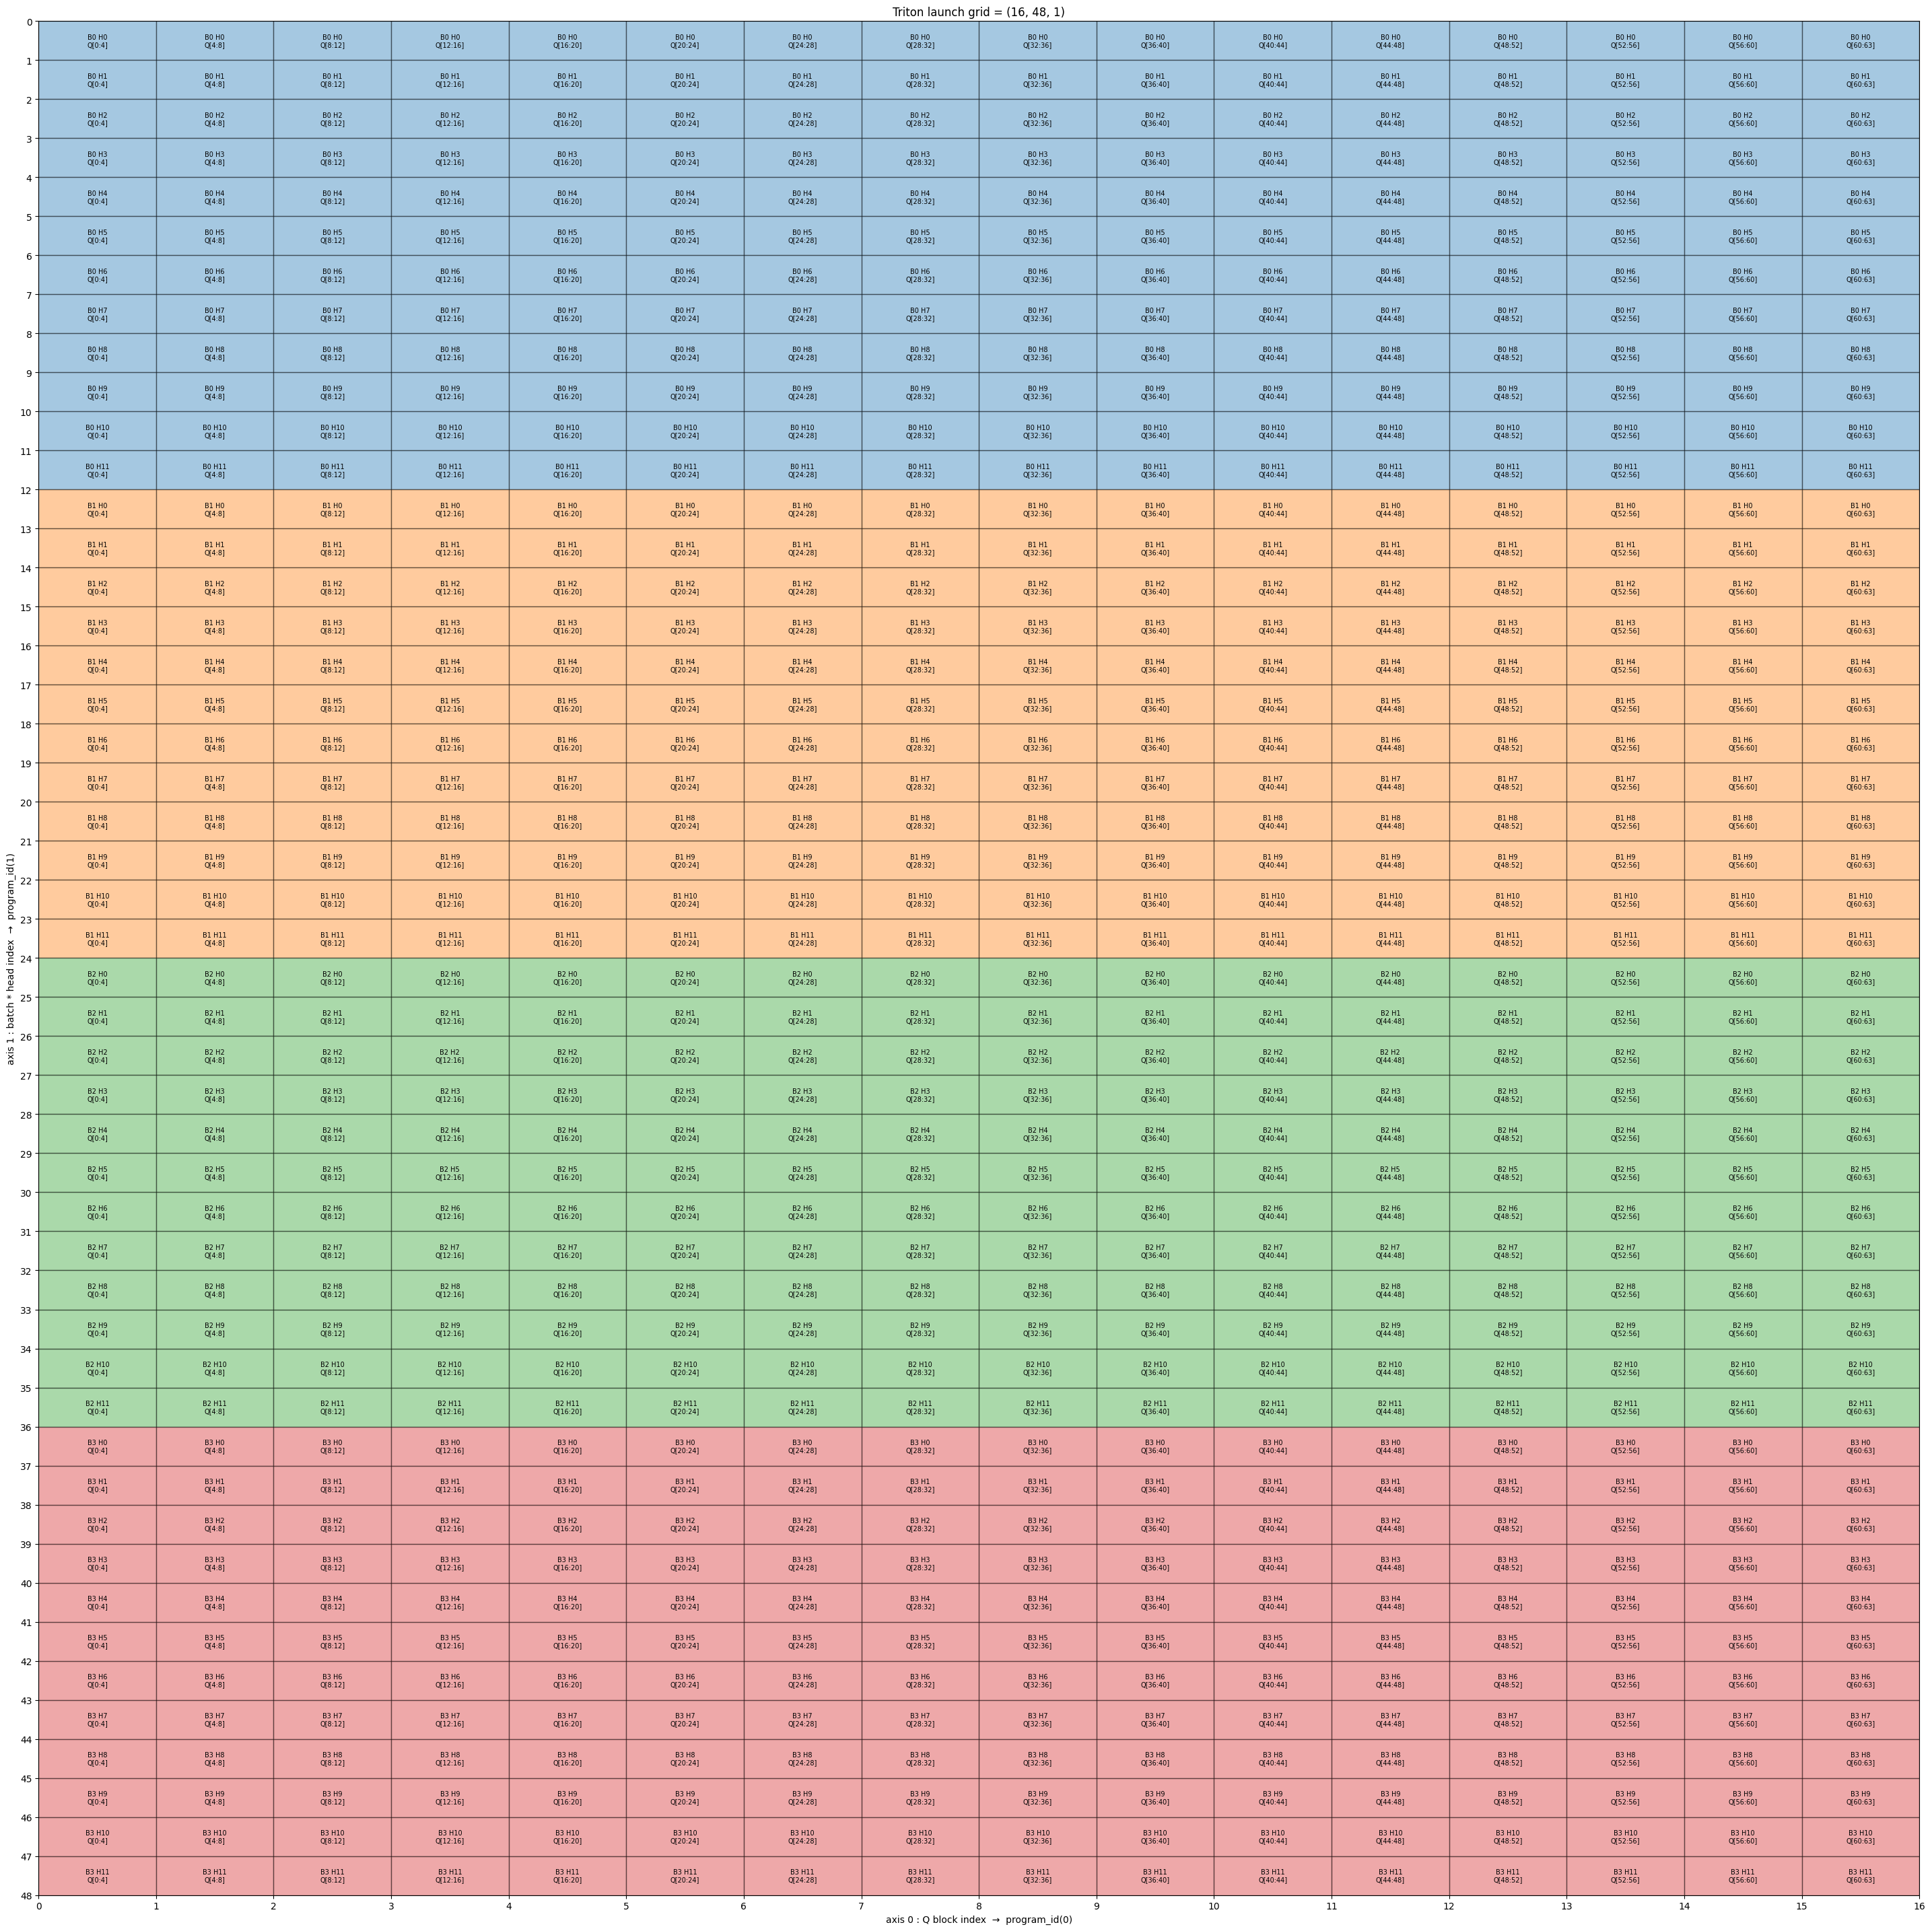

In [1]:
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches


def visualize_grid(BLOCK_SIZE_Q, BATCH_SIZE, NUM_HEADS, SEQ_LEN):
    num_q_blocks = math.ceil(SEQ_LEN / BLOCK_SIZE_Q)   # triton.cdiv(SEQ_LEN, BLOCK_SIZE_Q)
    num_bh = BATCH_SIZE * NUM_HEADS

    grid = (num_q_blocks, num_bh, 1)
    print(f"grid = {grid}  ->  {grid[0] * grid[1] * grid[2]} total Triton programs launched")

    fig, ax = plt.subplots(figsize=(num_q_blocks * 1.8, num_bh * 0.6))

    for bh in range(num_bh):
        batch_idx, head_idx = divmod(bh, NUM_HEADS)
        for qb in range(num_q_blocks):
            q_start = qb * BLOCK_SIZE_Q
            q_end = min(q_start + BLOCK_SIZE_Q, SEQ_LEN)
            color = plt.cm.tab10(batch_idx % 10)
            rect = patches.Rectangle((qb, bh), 1, 1, facecolor=color, alpha=0.4, edgecolor="black")
            ax.add_patch(rect)
            ax.text(
                qb + 0.5, bh + 0.5,
                f"B{batch_idx} H{head_idx}\nQ[{q_start}:{q_end}]",
                ha="center", va="center", fontsize=7,
            )

    ax.set_xlim(0, num_q_blocks)
    ax.set_ylim(0, num_bh)
    ax.set_xticks(range(num_q_blocks + 1))
    ax.set_yticks(range(num_bh + 1))
    ax.set_xlabel("axis 0 : Q block index  →  program_id(0)")
    ax.set_ylabel("axis 1 : batch * head index  →  program_id(1)")
    ax.set_title(f"Triton launch grid = {grid}")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

# same values used above: BATCH_SIZE=2, NUM_HEADS=8, SEQ_LEN=12
visualize_grid(BLOCK_SIZE_Q=4, BATCH_SIZE=4, NUM_HEADS=12, SEQ_LEN=63)
# Triton launch grid = 

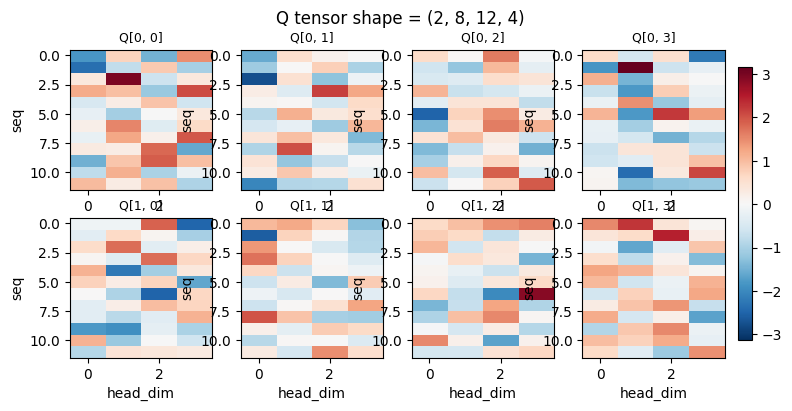

In [6]:
# Visualize just the Q tensor
import matplotlib.pyplot as plt
import torch 

def visualize_Q(Q, max_batches=2, max_heads=4):
    """
    Q: (BATCH, HEADS, SEQ, HEAD_DIM)
    Each subplot = one (batch, head) matrix: rows=tokens, cols=features
    """
    Q_cpu = Q.detach().float().cpu()
    B, H, S, D = Q_cpu.shape
    B_show = min(B, max_batches)
    H_show = min(H, max_heads)

    fig, axes = plt.subplots(
        B_show, H_show,
        figsize=(H_show * 2.2, B_show * 2.0),
        squeeze=False,
    )

    vmin, vmax = Q_cpu.min().item(), Q_cpu.max().item()

    for b in range(B_show):
        for h in range(H_show):
            ax = axes[b][h]
            im = ax.imshow(
                Q_cpu[b, h].numpy(),  # shape (SEQ_LEN, HEAD_DIM)
                aspect="auto",
                cmap="RdBu_r",
                vmin=vmin,
                vmax=vmax,
            )
            ax.set_title(f"Q[{b}, {h}]", fontsize=9)
            ax.set_xlabel("head_dim")
            ax.set_ylabel("seq")

    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    fig.suptitle(f"Q tensor shape = {tuple(Q.shape)}", fontsize=12)
    plt.show()

# Q tensor
BATCH_SIZE = 2
NUM_HEADS = 8
SEQ_LEN = 12
HEAD_DIM = 4
Q = torch.randn(BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM)
visualize_Q(Q)

In [ ]:
import torch
import triton 
import triton.language as tl 

class TritonAttention(torch.autograd.Function):
    @staticmethod
    def forward(ctx, Q, K, V, causal, softmax_scale):
        HEAD_DIM_Q, HEAD_DIM_K = Q.shape[-1], K.shape[-1]
        HEAD_DIM_V = V.shape[-1]

        BATCH_SIZE, NUM_HEADS, SEQ_LEN, HEAD_DIM = Q.shape

        assert HEAD_DIM_Q == HEAD_DIM_K and HEAD_DIM_K == HEAD_DIM_V
        